In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [2]:
# 读取city10.csv该数据代码
#你的代码
df=pd.read_csv("cities_10.csv",encoding="gbk")
df

,AREA,X1,X2,X3,X4,X5,X6,X7,X8,X9
0,辽宁,5458.2,13000,1376.2,2258.4,1315.9,529.0,2258.4,123.7,399.7
1,山东,10550.0,11643,3502.5,3851.0,2288.7,1070.7,3181.9,211.1,610.2
2,河北,6076.6,9047,1406.7,2092.6,1161.6,597.1,1968.3,45.9,302.3
3,天津,2022.6,22068,822.8,960.0,703.7,361.9,941.4,115.7,171.8
4,江苏,10636.3,14397,3536.3,3967.2,2320.0,1141.3,3215.8,384.7,643.7
5,上海,5408.8,40627,2196.2,2755.8,1970.2,779.3,2035.2,320.5,709.0
6,浙江,7670.0,16570,2356.5,3065.0,2296.6,1180.6,2877.5,294.2,566.9
7,福建,4682.0,13510,1047.1,1859.0,964.5,397.9,1663.3,173.7,272.9
8,广东,11769.7,15030,4224.6,4793.6,3022.9,1275.5,5013.6,1843.7,1201.6
9,广西,2455.4,5062,367.0,995.7,542.2,352.7,1025.5,15.1,186.7


In [3]:
#选取要用的特征
#你的代码
model_data=df.loc[:,"X1":]
model_data

,X1,X2,X3,X4,X5,X6,X7,X8,X9
0,5458.2,13000,1376.2,2258.4,1315.9,529.0,2258.4,123.7,399.7
1,10550.0,11643,3502.5,3851.0,2288.7,1070.7,3181.9,211.1,610.2
2,6076.6,9047,1406.7,2092.6,1161.6,597.1,1968.3,45.9,302.3
3,2022.6,22068,822.8,960.0,703.7,361.9,941.4,115.7,171.8
4,10636.3,14397,3536.3,3967.2,2320.0,1141.3,3215.8,384.7,643.7
5,5408.8,40627,2196.2,2755.8,1970.2,779.3,2035.2,320.5,709.0
6,7670.0,16570,2356.5,3065.0,2296.6,1180.6,2877.5,294.2,566.9
7,4682.0,13510,1047.1,1859.0,964.5,397.9,1663.3,173.7,272.9
8,11769.7,15030,4224.6,4793.6,3022.9,1275.5,5013.6,1843.7,1201.6
9,2455.4,5062,367.0,995.7,542.2,352.7,1025.5,15.1,186.7


# 使用主成分分析 手动确定几个主成分 来压缩信息

In [4]:
#查看相关系数 判断使用主成分分析 变量降维的必要性
#你的代码
corr_matrix=model_data.corr()
corr_matrix

,X1,X2,X3,X4,X5,X6,X7,X8,X9
X1,1.000000,-0.094292,0.966506,0.979238,0.922984,0.921680,0.941148,0.637458,0.825568
X2,-0.094292,1.000000,0.112726,0.074167,0.214052,0.093483,-0.042776,0.081195,0.273145
X3,0.966506,0.112726,1.000000,0.985373,0.963159,0.939194,0.935196,0.704714,0.898016
X4,0.979238,0.074167,0.985373,1.000000,0.972862,0.939720,0.962267,0.713890,0.913364
X5,0.922984,0.214052,0.963159,0.972862,1.000000,0.971337,0.937109,0.716722,0.934549
X6,0.921680,0.093483,0.939194,0.939720,0.971337,1.000000,0.897127,0.624294,0.848004
X7,0.941148,-0.042776,0.935196,0.962267,0.937109,0.897127,1.000000,0.836272,0.928692
X8,0.637458,0.081195,0.704714,0.713890,0.716722,0.624294,0.836272,1.000000,0.881528
X9,0.825568,0.273145,0.898016,0.913364,0.934549,0.848004,0.928692,0.881528,1.000000


In [5]:
#在使用主成分和聚类之前 应该？？？from sklearn.preprocessing import StandardScaler
#你的代码
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
scaler_model_data=scaler.fit_transform(model_data)
scaler_model_data

array([[-0.37574772, -0.33589708, -0.57070001, -0.33180084, -0.4351153 ,
        -0.68608742, -0.13882664, -0.44958874, -0.36008526],
       [ 1.19924012, -0.48315182,  1.14473196,  0.98455823,  0.79990984,
         0.8650543 ,  0.66401891, -0.27809633,  0.34976628],
       [-0.18446517, -0.76485655, -0.54609356, -0.46884237, -0.63100796,
        -0.49108511, -0.39102534, -0.60224445, -0.68853914],
       [-1.43844228,  0.6481162 , -1.01716572, -1.40498973, -1.21233816,
        -1.16457327, -1.28376177, -0.46528598, -1.12861338],
       [ 1.2259343 , -0.18430174,  1.17200074,  1.08060301,  0.83964698,
         1.06721529,  0.6934899 ,  0.0625339 ,  0.46273553],
       [-0.39102805,  2.66204455,  0.09085021,  0.07932373,  0.3955559 ,
         0.03063913, -0.33286576, -0.06343649,  0.68294126],
       [ 0.3084029 ,  0.05150118,  0.22017521,  0.33489213,  0.80993934,
         1.17974966,  0.39938849, -0.11504119,  0.20374931],
       [-0.61584072, -0.28055447, -0.83620754, -0.66192379, -0

In [6]:
#使用sklearn框架做主成分，判断主成分数量
#from sklearn.decomposition import PCA
#你的代码
from sklearn.decomposition import PCA

In [7]:
#实例化
pca=PCA(n_components=3)
model_data_scale=pca.fit(scaler_model_data)
model_data_scale

PCA(n_components=3)

In [8]:
np.set_printoptions(suppress=True)#阻止数字以科学计算输出 眼睛不好观察>0<
#输出主成分方差和占比 pca.explained_variance_
#你的代码
print("主成分可解释的变异：\n",pca.explained_variance_)
print("主成分可解释的变异的比例:\n",pca.explained_variance_ratio_)

主成分可解释的变异：
 [8.01129553 1.22149318 0.60792399]
主成分可解释的变异的比例:
 [0.80112955 0.12214932 0.0607924 ]


In [9]:
0.8+0.12


0.92

In [10]:
#根据结果 可见 选2个主成分可解释大部分数据

根据主成分个数来确定因子个数，为下面因子分析做准备

# 因子分析

In [11]:
#导入因子分析的包提取主成分，fa_kit是一个第三方的包 需要下载
#pip install fa_kit 我这里已经下载安装好了。。。

In [12]:
from fa_kit import FactorAnalysis
from fa_kit import plotting as fa_plotting#绘制因子载荷矩阵

In [13]:
#对输入的数据进行主成分提取
fa=FactorAnalysis.load_data_samples(
scaler_model_data,
preproc_demean=True,
preproc_scale=True)
fa.extract_components()

In [14]:
#设定提取主出发的方式，默认是broken_stick，建议使用top_n方法 fa.find
#你的代码
fa.find_comps_to_retain(method="top_n",num_keep=2)

array([0, 1], dtype=int64)

In [15]:
#通过最大方差法对因子进行旋转
#你的代码
fa.rotate_components(method="varimax")

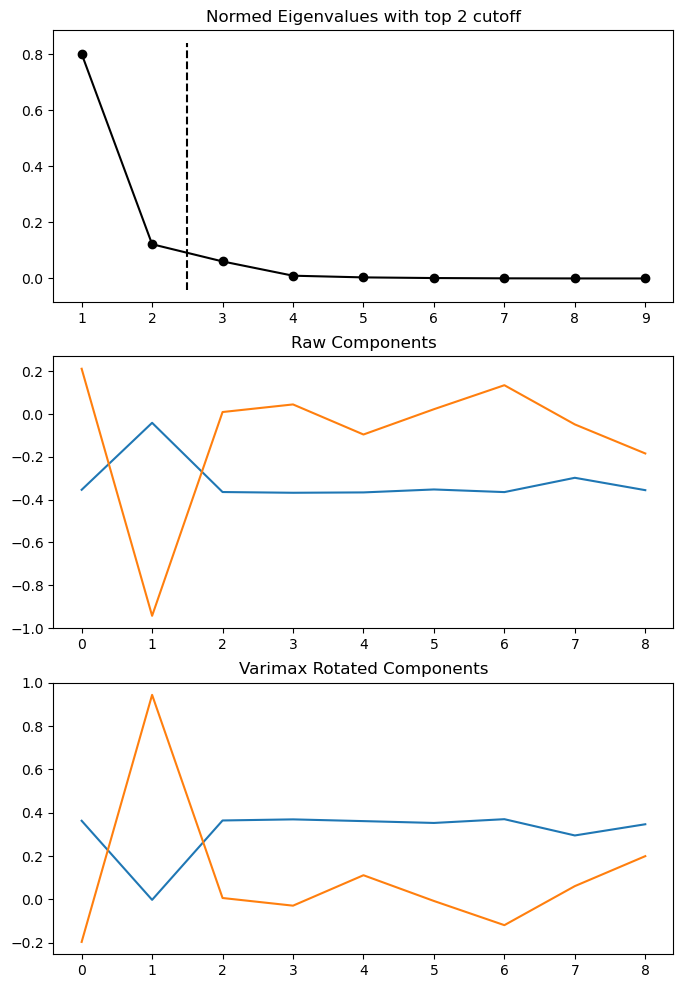

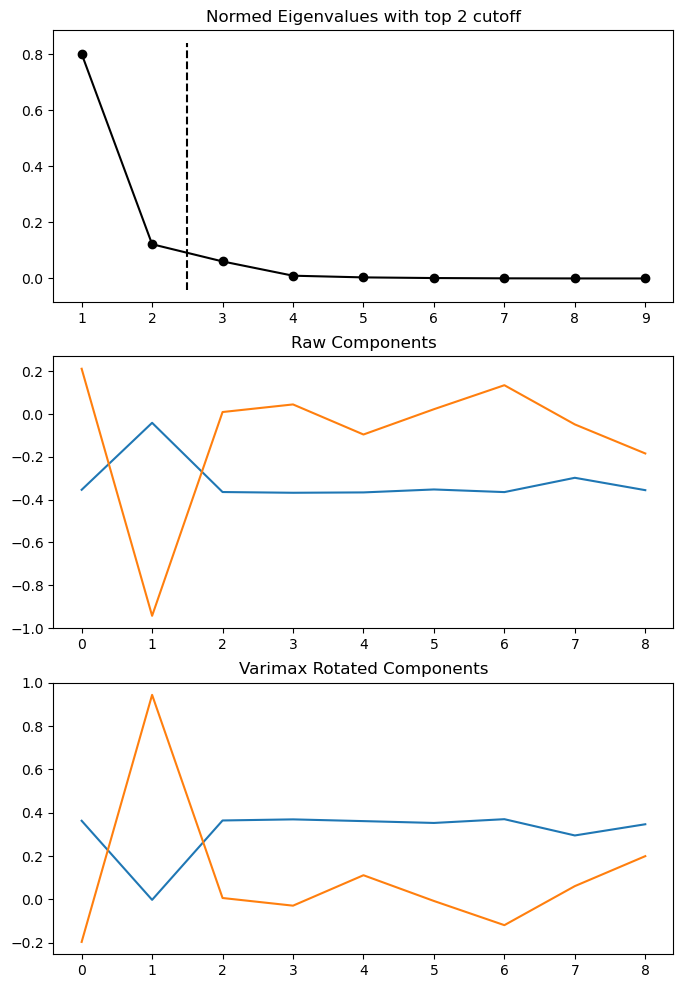

In [16]:
#可以绘制因子载荷矩阵图
fa_plotting.graph_summary(fa)
#第一张图解释了数据变异比例，第一个主成分解释了数据80%的变异，前两个主主成分已经大概能够解释原始数据了
#第二张图是在未旋转之前，各变量在因子中权重（载荷）每条折线表示一个因子，x轴个原始变量，y轴不同因子在各个变量上的权重
#第三张图方差最大化旋转后各个因子在各变量上的权重（载荷），观察此图，权重越高，代表性越强
#如果眼睛不喜欢看 emmm 那就看数，即打印因子载荷

In [17]:
#打印旋转后的因子权重
#你的代码
fa.comps["rot"]

array([[ 0.36287997, -0.19604704],
       [-0.00194704,  0.94364822],
       [ 0.36422208,  0.00656524],
       [ 0.36925509, -0.02877546],
       [ 0.36125764,  0.11159649],
       [ 0.35279873, -0.00714435],
       [ 0.37014035, -0.11869071],
       [ 0.29509869,  0.06139991],
       [ 0.34676526,  0.19965023]])

输出因子得分 拼接到原数据，对该数据进行层次聚类分析

In [18]:
#输出因子得分，为了方便拼接 转换成数据框
#你的代码n
fa_scores=fa.get_component_scores(scaler_model_data)
fa_scores=pd.DataFrame(fa_scores,columns=["Gross","Avg"])
fa_scores

,Gross,Avg
0,-1.174241,-0.364178
1,2.095775,-0.654819
2,-1.399899,-0.870629
3,-3.265185,0.698849
4,2.386557,-0.337666
5,0.163901,2.802894
6,1.209012,0.048116
7,-2.084500,-0.322173
8,5.501759,0.105138
9,-3.433179,-1.105531


In [19]:
#拼接原始数据
#你的代码
cities_fa_scores=df.join(fa_scores)
cities_fa_scores

,AREA,X1,X2,X3,X4,X5,X6,X7,X8,X9,Gross,Avg
0,辽宁,5458.2,13000,1376.2,2258.4,1315.9,529.0,2258.4,123.7,399.7,-1.174241,-0.364178
1,山东,10550.0,11643,3502.5,3851.0,2288.7,1070.7,3181.9,211.1,610.2,2.095775,-0.654819
2,河北,6076.6,9047,1406.7,2092.6,1161.6,597.1,1968.3,45.9,302.3,-1.399899,-0.870629
3,天津,2022.6,22068,822.8,960.0,703.7,361.9,941.4,115.7,171.8,-3.265185,0.698849
4,江苏,10636.3,14397,3536.3,3967.2,2320.0,1141.3,3215.8,384.7,643.7,2.386557,-0.337666
5,上海,5408.8,40627,2196.2,2755.8,1970.2,779.3,2035.2,320.5,709.0,0.163901,2.802894
6,浙江,7670.0,16570,2356.5,3065.0,2296.6,1180.6,2877.5,294.2,566.9,1.209012,0.048116
7,福建,4682.0,13510,1047.1,1859.0,964.5,397.9,1663.3,173.7,272.9,-2.084500,-0.322173
8,广东,11769.7,15030,4224.6,4793.6,3022.9,1275.5,5013.6,1843.7,1201.6,5.501759,0.105138
9,广西,2455.4,5062,367.0,995.7,542.2,352.7,1025.5,15.1,186.7,-3.433179,-1.105531


In [22]:
cities_fa_scores.to_csv("fa_cities_10.csv",index=False)#不是必须

# 层次聚类分析

In [23]:
#现在，对新的这份数据进行层次聚类分析
#你的代码
new_model_data=pd.read_csv("fa_cities_10.csv")
new_model_data

,AREA,X1,X2,X3,X4,X5,X6,X7,X8,X9,Gross,Avg
0,辽宁,5458.2,13000,1376.2,2258.4,1315.9,529.0,2258.4,123.7,399.7,-1.174241,-0.364178
1,山东,10550.0,11643,3502.5,3851.0,2288.7,1070.7,3181.9,211.1,610.2,2.095775,-0.654819
2,河北,6076.6,9047,1406.7,2092.6,1161.6,597.1,1968.3,45.9,302.3,-1.399899,-0.870629
3,天津,2022.6,22068,822.8,960.0,703.7,361.9,941.4,115.7,171.8,-3.265185,0.698849
4,江苏,10636.3,14397,3536.3,3967.2,2320.0,1141.3,3215.8,384.7,643.7,2.386557,-0.337666
5,上海,5408.8,40627,2196.2,2755.8,1970.2,779.3,2035.2,320.5,709.0,0.163901,2.802894
6,浙江,7670.0,16570,2356.5,3065.0,2296.6,1180.6,2877.5,294.2,566.9,1.209012,0.048116
7,福建,4682.0,13510,1047.1,1859.0,964.5,397.9,1663.3,173.7,272.9,-2.084500,-0.322173
8,广东,11769.7,15030,4224.6,4793.6,3022.9,1275.5,5013.6,1843.7,1201.6,5.501759,0.105138
9,广西,2455.4,5062,367.0,995.7,542.2,352.7,1025.5,15.1,186.7,-3.433179,-1.105531


In [24]:
#画图，肉眼先看看分成几类，这些城市，
plt.rcParams['font.family'] = 'SimHei'
from pylab import mpl
mpl.rcParams['axes.unicode_minus'] = False 

def scatter(x, y, labels, **kw):
    
    plt.figure(figsize=(6, 4))
    plt.yticks(size=12)
    plt.xticks(size=12)
    plt.scatter(x, y)
    for xx, yy, label in zip(x, y, labels):
        plt.text(xx, yy, '%s.' % label, 
                 ha='center', va='bottom', **kw)
plt.show()


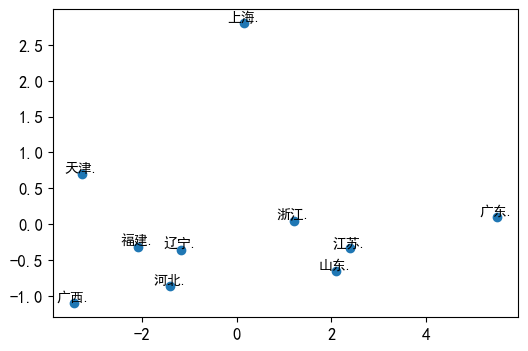

In [25]:
# 画图，x,y，标签
#你的代码
x=new_model_data["Gross"]
y=new_model_data["Avg"]
labels=new_model_data["AREA"]
scatter(x,y,labels)

因子分析后 开始对拼接后的数据进行层次聚类分析

In [26]:
#层次聚类 导入包
import scipy.cluster.hierarchy as sch

In [27]:
#计算距离 生成点与点欧式距离矩阵
#你的代码
dis_mat=sch.distance.pdist(new_model_data[["Gross","Avg"]],metric='euclidean')

In [28]:
#搭建层次聚类模型,类与类链接
#你的代码
Z=sch.linkage(dis_mat,method="ward")
Z

array([[ 1.        ,  4.        ,  0.43027829,  2.        ],
       [ 0.        ,  2.        ,  0.55445008,  2.        ],
       [ 7.        , 11.        ,  0.98187246,  3.        ],
       [ 6.        , 10.        ,  1.34742622,  3.        ],
       [ 3.        ,  9.        ,  1.81218392,  2.        ],
       [12.        , 14.        ,  2.82545755,  5.        ],
       [ 5.        , 13.        ,  4.36874882,  4.        ],
       [ 8.        , 16.        ,  5.127847  ,  5.        ],
       [15.        , 17.        , 10.30873462, 10.        ]])

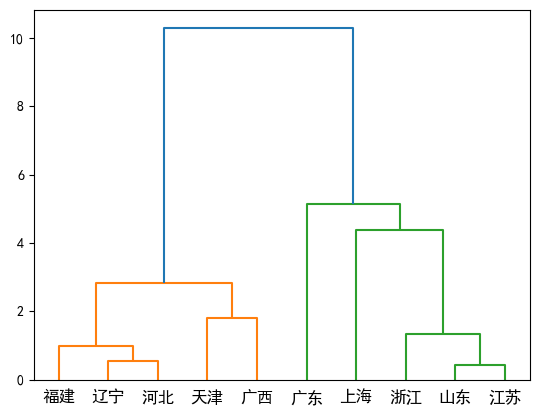

In [29]:
#将层次聚类结果用层次聚类图展示出来，plt.savefig('plot_dendrogram.png')
#你的代码
P=sch.dendrogram(Z,labels=new_model_data["AREA"].tolist())
plt.savefig("plot_dendrogram.png")